In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
from scipy.stats import pearsonr

#load the csv file
df = pd.read_csv("dry curly hair data/Extension_Dry_2000mmmin_C_sorted_by_strain_cleaned.csv")
print(df)

     Record  Strain (%)  Stress (MPa)
0         1         0.0           0.3
1         1         0.0          -0.1
2         2         0.0           0.2
3         2         0.0           0.1
4         3         0.0          -0.1
..      ...         ...           ...
259      23         3.5           0.3
260      24         3.5           0.4
261       8         3.6           0.7
262      20         3.6           1.6
263      25         3.6           2.4

[264 rows x 3 columns]


In [8]:
#Convert columns to numbers
df["Strain (%)"] = pd.to_numeric(df["Strain (%)"], errors='coerce')
df["Stress (MPa)"] = pd.to_numeric(df["Stress (MPa)"], errors='coerce')
df = df.dropna(subset=["Strain (%)", "Stress (MPa)"])  # Drop rows with NaN values in these columns

#Sort by strain
df = df.sort_values("Strain (%)")

#Check the data
print(df.head())
print(df.info())

   Record  Strain (%)  Stress (MPa)
0       1         0.0           0.3
1       1         0.0          -0.1
2       2         0.0           0.2
3       2         0.0           0.1
4       3         0.0          -0.1
<class 'pandas.core.frame.DataFrame'>
Index: 264 entries, 0 to 263
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Record        264 non-null    int64  
 1   Strain (%)    264 non-null    float64
 2   Stress (MPa)  264 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 8.2 KB
None


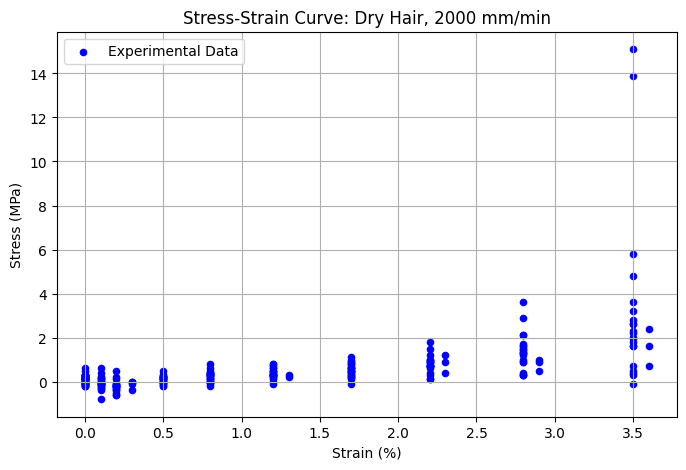

In [9]:
plt.figure(figsize=(8, 5)) #Raw stress-strain data
plt.scatter(df["Strain (%)"], df["Stress (MPa)"], s=20, label = "Experimental Data", color='blue')

plt.xlabel("Strain (%)")
plt.ylabel("Stress (MPa)")
plt.title("Stress-Strain Curve: Dry Hair, 2000 mm/min")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
mean_df = (df.groupby("Strain (%)")["Stress (MPa)"].agg(['mean', 'std']).reset_index())
print(mean_df)

    Strain (%)      mean       std
0          0.0  0.089583  0.174111
1          0.1 -0.045833  0.271836
2          0.2 -0.200000  0.266667
3          0.3 -0.100000  0.173205
4          0.5  0.091667  0.163964
5          0.8  0.225000  0.236367
6          1.2  0.377273  0.234890
7          1.3  0.250000  0.070711
8          1.7  0.525000  0.299637
9          2.2  0.795238  0.405557
10         2.3  0.833333  0.404145
11         2.8  1.390476  0.825170
12         2.9  0.800000  0.264575
13         3.5  3.319048  3.991318
14         3.6  1.566667  0.850490


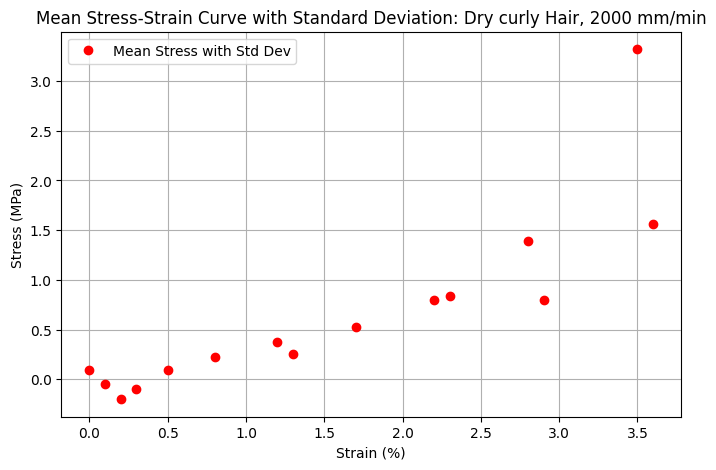

In [11]:
plt.figure(figsize=(8, 5)) 
plt.errorbar(mean_df["Strain (%)"], mean_df["mean"], fmt='o', label='Mean Stress with Std Dev', color='red', capsize=3)

plt.xlabel("Strain (%)")
plt.ylabel("Stress (MPa)")
plt.title("Mean Stress-Strain Curve with Standard Deviation: Dry curly Hair, 2000 mm/min")
plt.legend()
plt.grid(True)
plt.show()

In [12]:
strain = mean_df["Strain (%)"].values
stress = mean_df["mean"].values

#Define the exponential model
def exponential(x, A, B):
    return A * (np.exp(B * x) - 1)

# 3. Set minimum number of points
# ==========================================

MIN_POINTS_TOE = 8
MIN_POINTS_ELASTIC = 6

# 4. Define possible breakpoints
# ==========================================

# Only search between these strain values
min_breakpoint = 0.01
max_breakpoint = 4.6

possible_breakpoints = np.linspace(min_breakpoint,max_breakpoint,100)

#5. Store results
# ==========================================

results = []


# 6. Test every possible breakpoint
# ==========================================
# loop through each possible breakpoint and fit the toe and elastic regions separately, then calculate the MSE for each fit.
for breakpoint in possible_breakpoints:

    # -----------------------------
    # Divide data
    # -----------------------------

    toe_mask = strain <= breakpoint
    elastic_mask = strain > breakpoint

    toe_strain = strain[toe_mask]
    toe_stress = stress[toe_mask]

    elastic_strain = strain[elastic_mask]
    elastic_stress = stress[elastic_mask]


    # -----------------------------
    # Minimum point requirement
    # -----------------------------

    if len(toe_strain) < MIN_POINTS_TOE:
        continue

    if len(elastic_strain) < MIN_POINTS_ELASTIC:
        continue


    # ==========================================
    # 7. Fit exponential to toe region
    # ==========================================

    try:

        popt_exp, _ = curve_fit(
            exponential,
            toe_strain,
            toe_stress,
            p0=[1, 1],
            maxfev=10000
        )

    except RuntimeError:

        continue


    A, B = popt_exp


    # Predicted toe stresses

    predicted_toe = exponential(
        toe_strain,
        A,
        B
    )


    # ==========================================
    # 8. Fit linear elastic region
    # ==========================================

    stress_at_breakpoint = exponential(breakpoint, A, B)
    strain_offset = elastic_strain - breakpoint

    E = np.sum(
        strain_offset * (elastic_stress - stress_at_breakpoint)
    ) / np.sum(strain_offset ** 2)
    C = stress_at_breakpoint - E * breakpoint


    # Predicted elastic stresses

    predicted_elastic = (
        E * elastic_strain + C
    )


    # ==========================================
    # 9. Calculate MSE
    # ==========================================

    toe_mse = np.mean(
        (toe_stress - predicted_toe) ** 2
    )

    elastic_mse = np.mean(
        (elastic_stress - predicted_elastic) ** 2
    )


    # ==========================================
    # 10. Combined MSE
    # ==========================================

    total_mse = toe_mse + elastic_mse #total MSE is the sum of the toe and elastic MSEs


    # ==========================================
    # 11. Store results
    # ==========================================

    results.append({
        "breakpoint": breakpoint,
        "toe_mse": toe_mse,
        "elastic_mse": elastic_mse,
        "total_mse": total_mse,
        "A": A,
        "B": B,
        "E": E,
        "C": C,
        "n_toe": len(toe_strain),
        "n_elastic": len(elastic_strain)
    })


#12. Convert results to DataFrame
# ==========================================

results_df = pd.DataFrame(results)


# ==========================================
# 13. Find best breakpoint
# ==========================================

best_index = results_df["total_mse"].idxmin()

best_result = results_df.loc[best_index]


print("\nBEST BREAKPOINT")
print("----------------------")

print(
    "Breakpoint strain:",
    best_result["breakpoint"]
)

print(
    "Toe MSE:",
    best_result["toe_mse"]
)

print(
    "Elastic MSE:",
    best_result["elastic_mse"]
)

print(
    "Total MSE:",
    best_result["total_mse"]
)

print(
    "Number of toe points:",
    int(best_result["n_toe"])
)

print(
    "Number of elastic points:",
    int(best_result["n_elastic"])
)

print("\nToe exponential parameters")

print(
    "A =",
    best_result["A"]
)

print(
    "B =",
    best_result["B"]
)

print("\nElastic linear parameters")

print(
    "E =",
    best_result["E"]
)

print(
    "C =",
    best_result["C"]
)


BEST BREAKPOINT
----------------------
Breakpoint strain: 1.54
Toe MSE: 0.012867087650702196
Elastic MSE: 0.3800105039700133
Total MSE: 0.3928775916207155
Number of toe points: 8
Number of elastic points: 7

Toe exponential parameters
A = 0.07113344620837296
B = 1.344690459174135

Elastic linear parameters
E = 0.7771533969731395
C = -0.7037653927987146


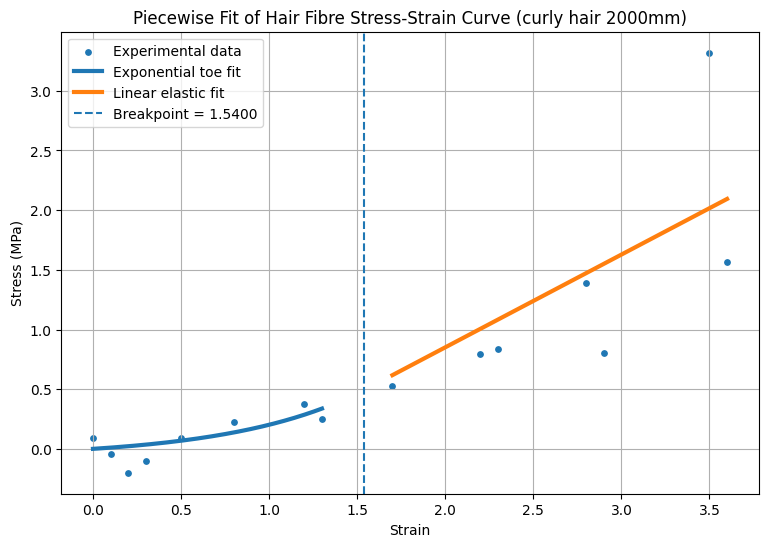

In [13]:
best_breakpoint = best_result["breakpoint"]

toe_mask = strain <= best_breakpoint
elastic_mask = strain > best_breakpoint

toe_strain = strain[toe_mask]
toe_stress = stress[toe_mask]

elastic_strain = strain[elastic_mask]
elastic_stress = stress[elastic_mask]


# Exponential fit

A = best_result["A"]
B = best_result["B"]

toe_x = np.linspace(
    toe_strain.min(),
    toe_strain.max(),
    200
)

toe_y = exponential(
    toe_x,
    A,
    B
)


# Linear fit

E = best_result["E"]
C = best_result["C"]

elastic_x = np.linspace(
    elastic_strain.min(),
    elastic_strain.max(),
    200
)

elastic_y = E * elastic_x + C


# Plot

plt.figure(figsize=(9, 6))

plt.scatter(
    strain,
    stress,
    s=15,
    label="Experimental data"
)

plt.plot(
    toe_x,
    toe_y,
    linewidth=3,
    label="Exponential toe fit"
)

plt.plot(
    elastic_x,
    elastic_y,
    linewidth=3,
    label="Linear elastic fit"
)

plt.axvline(
    best_breakpoint,
    linestyle="--",
    label=f"Breakpoint = {best_breakpoint:.4f}"
)

plt.xlabel("Strain")
plt.ylabel("Stress (MPa)")
plt.title("Piecewise Fit of Hair Fibre Stress-Strain Curve (curly hair 2000mm)")

plt.legend()
plt.grid(True)

plt.show()

In [14]:
breakpoint = best_breakpoint

toe_mask = strain <= breakpoint
elastic_mask = strain > breakpoint

toe_strain = strain[toe_mask]
toe_stress = stress[toe_mask]

elastic_strain = strain[elastic_mask]
elastic_stress = stress[elastic_mask]

# 2. Calculate predicted stress
# ------------------------------------------

def exponential(x, A, B):
    return A * (np.exp(B * x) - 1)

predicted_toe = exponential(toe_strain, A, B)
predicted_elastic = E * elastic_strain + C

# 3. Toe-region length
# ------------------------------------------

toe_length = breakpoint - np.min(strain)

# ------------------------------------------
# 4. Stress at transition
# ------------------------------------------

stress_transition_toe = exponential(breakpoint, A, B)
stress_transition_elastic = E * breakpoint + C

# Difference between the two models at the breakpoint
transition_gap = stress_transition_elastic - stress_transition_toe

# 5. Effective toe-region stiffness
# ------------------------------------------

# Derivative of A*(exp(B*strain) - 1)
toe_stiffness_transition = A * B * np.exp(B * breakpoint)

# ------------------------------------------
# 6. Elastic modulus
# ------------------------------------------

elastic_modulus = E

# 7. Correlation and R-squared
# ------------------------------------------

def calculate_metrics(observed, predicted):
    residuals = observed - predicted

    sse = np.sum(residuals ** 2)
    mse = np.mean(residuals ** 2)
    rmse = np.sqrt(mse)

    sst = np.sum((observed - np.mean(observed)) ** 2)

    r_squared = 1 - sse / sst if sst > 0 else np.nan

    # Pearson correlation is undefined for constant arrays
    if (
        len(observed) >= 2
        and np.std(observed) > 0
        and np.std(predicted) > 0
    ):
        r = pearsonr(observed, predicted).statistic
    else:
        r = np.nan

    return {
        "r": r,
        "R_squared": r_squared,
        "SSE": sse,
        "MSE": mse,
        "RMSE": rmse,
        "residuals": residuals
    }

toe_metrics = calculate_metrics(toe_stress, predicted_toe)
elastic_metrics = calculate_metrics(elastic_stress, predicted_elastic)

all_stress = np.concatenate([toe_stress, elastic_stress])
all_predicted = np.concatenate([predicted_toe, predicted_elastic])

overall_metrics = calculate_metrics(all_stress, all_predicted)
regional_mse_sum = toe_metrics["MSE"] + elastic_metrics["MSE"]

# ------------------------------------------
# 8. Print results
# ------------------------------------------

print("\n===== HAIR FIBRE ANALYSIS =====")

print(f"Breakpoint strain: {breakpoint:.6f}")
print(f"Toe-region length: {toe_length:.6f}")

print("\nStress at transition:")
print(f"Exponential fit: {stress_transition_toe:.6f}")
print(f"Linear fit:      {stress_transition_elastic:.6f}")
print(f"Transition gap:  {transition_gap:.6f}")

print("\nToe-region stiffness at transition:")
print(f"{toe_stiffness_transition:.6f} stress units per strain unit")

print("\nElastic modulus:")
print(f"{elastic_modulus:.6f} stress units per strain unit")

print(f"\nRegional MSE sum (toe + elastic): {regional_mse_sum:.6f}")

for name, metrics in [
    ("TOE REGION", toe_metrics),
    ("ELASTIC REGION", elastic_metrics),
    ("OVERALL", overall_metrics)
]:
    print(f"\n{name}")
    print(f"Pearson r: {metrics['r']:.5f}")
    print(f"R-squared: {metrics['R_squared']:.5f}")
    print(f"SSE:       {metrics['SSE']:.6f}")
    mse_label = "Overall pooled MSE" if name == "OVERALL" else "MSE"
    print(f"{mse_label}: {metrics['MSE']:.6f}")
    print(f"RMSE:      {metrics['RMSE']:.6f}")


===== HAIR FIBRE ANALYSIS =====
Breakpoint strain: 1.540000
Toe-region length: 1.540000

Stress at transition:
Exponential fit: 0.493051
Linear fit:      0.493051
Transition gap:  0.000000

Toe-region stiffness at transition:
0.758653 stress units per strain unit

Elastic modulus:
0.777153 stress units per strain unit

Regional MSE sum (toe + elastic): 0.392878

TOE REGION
Pearson r: 0.80570
R-squared: 0.61137
SSE:       0.102937
MSE: 0.012867
RMSE:      0.113433

ELASTIC REGION
Pearson r: 0.74577
R-squared: 0.51429
SSE:       2.660074
MSE: 0.380011
RMSE:      0.616450

OVERALL
Pearson r: 0.87333
R-squared: 0.75791
SSE:       2.763010
Overall pooled MSE: 0.184201
RMSE:      0.429186


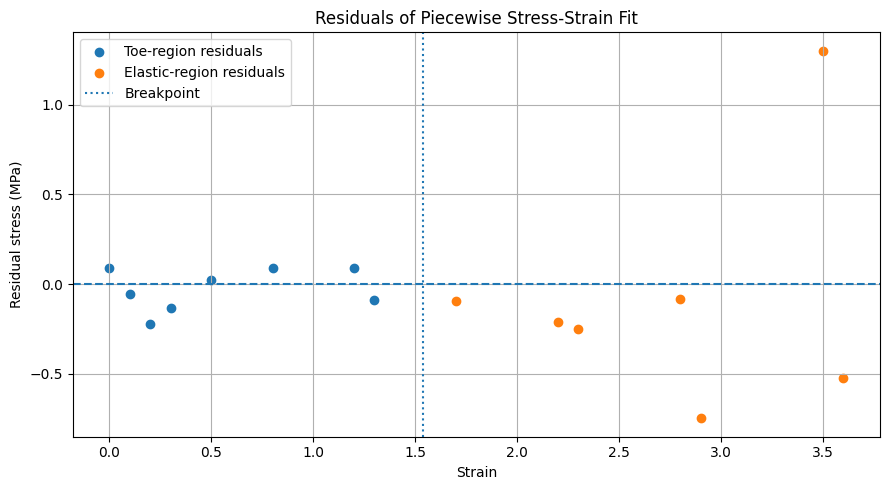

In [15]:
toe_residuals = toe_stress - predicted_toe
elastic_residuals = elastic_stress - predicted_elastic

plt.figure(figsize=(9, 5))

plt.scatter(
    toe_strain, toe_residuals,
    label="Toe-region residuals"
)

plt.scatter(
    elastic_strain, elastic_residuals,
    label="Elastic-region residuals"
)

plt.axhline(0, linestyle="--")

plt.axvline(
    breakpoint,
    linestyle=":",
    label="Breakpoint"
)

plt.xlabel("Strain")
plt.ylabel("Residual stress (MPa)")
plt.title("Residuals of Piecewise Stress-Strain Fit")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Breakpoint strain: 1.700000
Toe-region length: 1.700000
Toe transition stress: 0.572812
Elastic transition stress: 0.280571
Transition stress gap: -0.292241
Toe stiffness at transition: 0.618436
Elastic modulus: 1.023348
Toe R-squared: 0.6727
Elastic R-squared: 0.5562
Overall R-squared: 0.7794
Regional MSE sum (toe + elastic): 0.358074
Overall pooled MSE (all points): 0.167824
Toe MSE: 0.010837
Elastic MSE: 0.347237


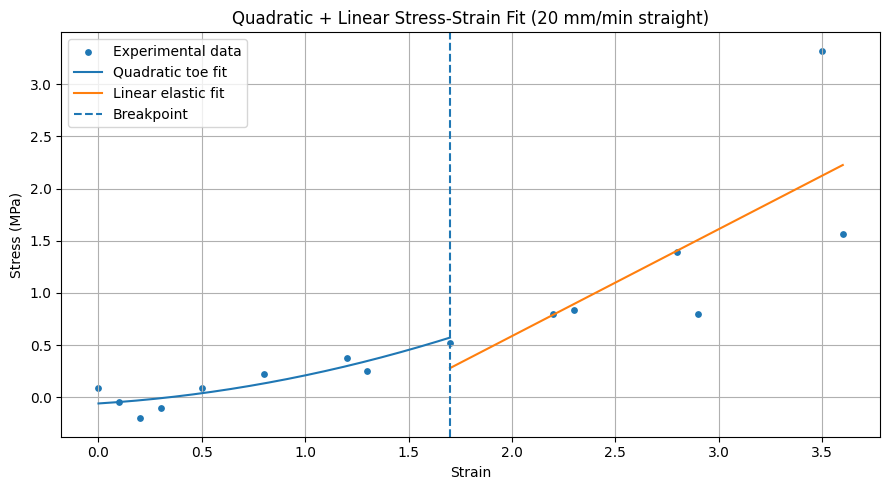

In [16]:
def quadratic(x, a, b, c):
    return a * x**2 + b * x + c

def linear(x, E, d):
    return E * x + d

min_points_toe =8  #toe region
min_points_elastic = 4
results = []

# Sort data by strain
order = np.argsort(strain)
strain = np.asarray(strain, dtype=float)[order]
stress = np.asarray(stress, dtype=float)[order]


# Search candidate breakpoints
for i in range(min_points_toe, len(strain) - min_points_elastic + 1):

    breakpoint = strain[i]

    toe_x, toe_y = strain[:i], stress[:i]
    elastic_x, elastic_y = strain[i:], stress[i:]

    # Fit quadratic toe region
    a, b, c = np.polyfit(toe_x, toe_y, 2)
    toe_pred = quadratic(toe_x, a, b, c)

    # Fit linear elastic region
    E, d = np.polyfit(elastic_x, elastic_y, 1)
    elastic_pred = linear(elastic_x, E, d)

    # Mean squared errors
    toe_mse = np.mean((toe_y - toe_pred)**2)
    elastic_mse = np.mean((elastic_y - elastic_pred)**2)

    # Sum of regional MSEs scores each region equally
    regional_mse_sum = toe_mse + elastic_mse
    all_squared_errors = np.concatenate((
        (toe_y - toe_pred)**2,
        (elastic_y - elastic_pred)**2
    ))
    overall_pooled_mse = np.mean(all_squared_errors)

    results.append({
        "breakpoint": breakpoint,
        "index": i,
        "a": a, "b": b, "c": c,
        "E": E, "d": d,
        "toe_mse": toe_mse,
        "elastic_mse": elastic_mse,
        "regional_mse_sum": regional_mse_sum,
        "overall_pooled_mse": overall_pooled_mse
    })



results_df = pd.DataFrame(results)

if results_df.empty:
    raise ValueError("No valid breakpoint was found.")

best_result = results_df.loc[
    results_df["regional_mse_sum"].idxmin()
]

# Extract the best fit
i = int(best_result["index"])
breakpoint = float(best_result["breakpoint"])

toe_x, toe_y = strain[:i], stress[:i]
elastic_x, elastic_y = strain[i:], stress[i:]

a, b, c = best_result[["a", "b", "c"]]
E, d = best_result[["E", "d"]]

toe_pred = quadratic(toe_x, a, b, c)
elastic_pred = linear(elastic_x, E, d)

# Research parameters
toe_length = breakpoint - strain.min()
toe_transition_stress = quadratic(breakpoint, a, b, c)
elastic_transition_stress = linear(breakpoint, E, d)
toe_stiffness = 2 * a * breakpoint + b
elastic_modulus = E

def r_squared(y, y_pred):
    sse = np.sum((y - y_pred)**2)
    sst = np.sum((y - np.mean(y))**2)
    return 1 - sse / sst if sst > 0 else np.nan

toe_r2 = r_squared(toe_y, toe_pred)
elastic_r2 = r_squared(elastic_y, elastic_pred)

all_pred = np.concatenate([toe_pred, elastic_pred])
overall_r2 = r_squared(stress, all_pred)

# Summary for this test
print(f"Breakpoint strain: {breakpoint:.6f}")
print(f"Toe-region length: {toe_length:.6f}")
print(f"Toe transition stress: {toe_transition_stress:.6f}")
print(f"Elastic transition stress: {elastic_transition_stress:.6f}")
print(f"Transition stress gap: "
      f"{elastic_transition_stress - toe_transition_stress:.6f}")
print(f"Toe stiffness at transition: {toe_stiffness:.6f}")
print(f"Elastic modulus: {elastic_modulus:.6f}")
print(f"Toe R-squared: {toe_r2:.4f}")
print(f"Elastic R-squared: {elastic_r2:.4f}")
print(f"Overall R-squared: {overall_r2:.4f}")
print(f"Regional MSE sum (toe + elastic): {best_result['regional_mse_sum']:.6f}")
print(f"Overall pooled MSE (all points): {best_result['overall_pooled_mse']:.6f}")

toe_mse = float(best_result["toe_mse"])
elastic_mse = float(best_result["elastic_mse"])

print(f"Toe MSE: {toe_mse:.6f}")
print(f"Elastic MSE: {elastic_mse:.6f}")

# Plot fitted curve
plt.figure(figsize=(9, 5))
plt.scatter(strain, stress, s=15, label="Experimental data")

x_toe = np.linspace(toe_x.min(), breakpoint, 150)
x_elastic = np.linspace(breakpoint, elastic_x.max(), 150)

plt.plot(x_toe, quadratic(x_toe, a, b, c),
         label="Quadratic toe fit")
plt.plot(x_elastic, linear(x_elastic, E, d),
         label="Linear elastic fit")
plt.axvline(breakpoint, linestyle="--", label="Breakpoint")

plt.xlabel("Strain")
plt.ylabel("Stress (MPa)")
plt.title("Quadratic + Linear Stress-Strain Fit (20 mm/min straight)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


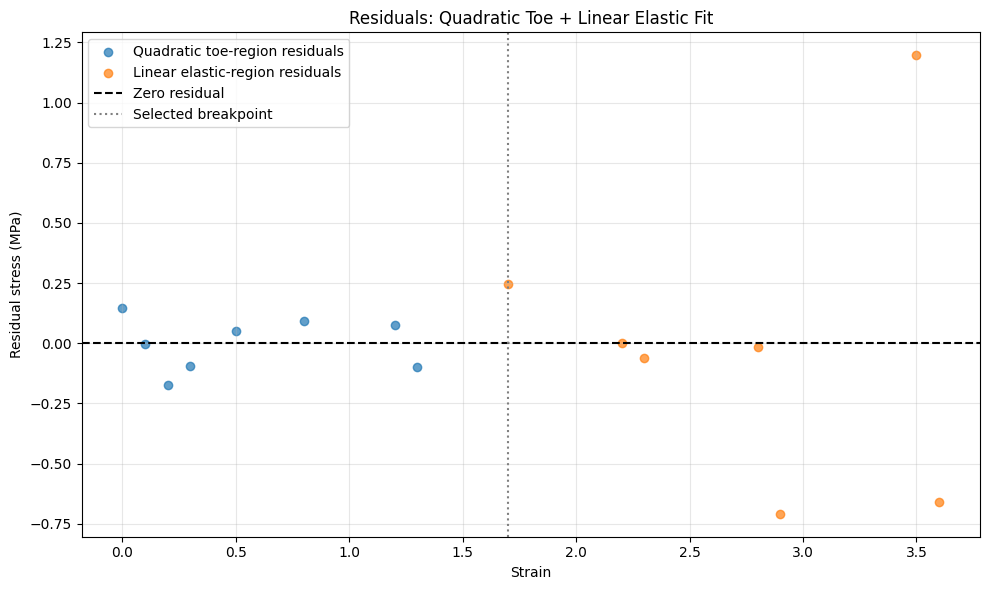

In [17]:
# Calculate residuals for the quadratic model
quad_toe_residuals = toe_y - toe_pred

# Calculate residuals for the linear elastic model
quad_elastic_residuals = elastic_y - elastic_pred

# Create residual graph
plt.figure(figsize=(10, 6))

plt.scatter(
    toe_x,
    quad_toe_residuals,
    label="Quadratic toe-region residuals",
    alpha=0.7
)

plt.scatter(
    elastic_x,
    quad_elastic_residuals,
    label="Linear elastic-region residuals",
    alpha=0.7
)

# Reference line at zero
plt.axhline(
    y=0,
    linestyle="--",
    color="black",
    label="Zero residual"
)

# Mark the selected breakpoint
plt.axvline(
    x=breakpoint,
    linestyle=":",
    color="grey",
    label="Selected breakpoint"
)

plt.xlabel("Strain")
plt.ylabel("Residual stress (MPa)")
plt.title("Residuals: Quadratic Toe + Linear Elastic Fit")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
